# 4장 word2vec 속도 개선 — 한글 실습: 음악 말뭉치로 word2vec 학습·평가하기

교재 4장 한글 예제(`word2vec_korean.ipynb`, 김소월 시 168편)와 같은 흐름으로, **음악 분야 한글 말뭉치**를 직접 모아
교재의 CBOW(Embedding + 네거티브 샘플링) 코드로 학습하고 평가합니다.

김소월 예제는 말뭉치가 1.3만 토큰뿐이라 `<unk>`가 30%였고, `most_similar('님')`이 `몹쓸`, `물가`를 내놓을 만큼 결과가 불안정했습니다.
이번 실습은 그 한계를 보완하는 데 초점을 둡니다.

| | 김소월 예제 | 이 노트북 |
|---|---|---|
| 말뭉치 | 시 168편, 1.3만 토큰 | 위키백과 음악 문서 약 2만 편, 약 500만 토큰 |
| 토크나이저 | 규칙 기반 조사 분리 | 규칙 기반 vs 형태소 분석기(Kiwi) 비교 |
| 평가 | `most_similar` 몇 개 (정성) | 정성 평가 + **직접 만든 유추 374문항, 범주 군집 평가** (정량) |
| 실험 | 기본 설정 1회 | 토크나이저 / CBOW·Skip-gram / 윈도우 / 말뭉치 크기 비교 |

구성: 1) 말뭉치 수집 → 2) 토크나이저 → 3) 단어 ID 변환 → 4) 학습 → 5) 평가 → 6) 비교 실험 → 7) 시각화 → 8) 고찰

In [1]:
# some helper functions for Colab
def is_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

if is_colab():
    !git clone --depth 1 https://github.com/rkdgusdh/deep_learning_from_scratch.git
    %cd deep_learning_from_scratch/word2vec_music
    !pip -q install kiwipiepy
    !apt-get -qq install fonts-nanum > /dev/null   # 그래프의 한글 표시용 폰트
    import matplotlib.font_manager as fm; fm._load_fontmanager(try_read_cache=False)

import sys, os, glob, pickle, collections
sys.path.insert(0, os.getcwd())   # word2vec_music/common (밑바닥 2권 공통 코드)을 쓴다
import numpy as np
import matplotlib.pyplot as plt
from common.korean import set_korean_font
set_korean_font()

matplotlib 한글 폰트: NanumGothic


'NanumGothic'

## 1. 말뭉치: 한국어 위키백과 음악 문서

**출처.** [kowikitext](https://github.com/lovit/kowikitext)는 한국어 위키백과 덤프(2020-09-20)를 문서 단위 텍스트로 정리한 공개 데이터입니다(CC BY-SA, 위키백과와 동일).
김소월 예제가 위키문헌에서 시를 가져온 것처럼, 위키백과에서 음악 문서만 골라 씁니다.

**음악 문서 고르기** (`dataset/filter_music.py`). 위키백과 문서의 첫 문장은 `《First Love》는 이루마의 두 번째 정규 음반이다.`처럼 정의문입니다.
정의문의 서술부(끝 40글자)에 `가수, 음반, 노래, 작곡가, 밴드, 교향곡, 오페라, 악기, 장르 ...` 같은 음악 명사가 있으면 음악 문서로 봅니다.
처음에는 정의문 전체에서 키워드를 찾았더니 `조세법률주의`(…), `FN M1900`(싱글 액션 권총), `안남초등학교`(연주리에 있는…) 같은 문서가 섞여 들어와서 서술부만 보도록 좁혔습니다.

**정제** (`dataset/clean_music.py`). 괄호 속 원어·한자·생몰년을 지우고, `~다.`로 끝나는 서술문만 남기고(트랙 목록·표·연표 줄 제거), 문서 안의 중복 문장을 지웠습니다.
한글 비율이 60% 미만인 문장(영어 가사·곡 제목 나열)도 뺐습니다.

전체 과정은 `dataset/make_music.sh`로 다시 만들 수 있고(약 500MB 다운로드), 저장소에는 정제본 `dataset/music_clean.txt.gz`만 넣었습니다.

In [2]:
import gzip
docs = []   # [(제목, [문장, ...]), ...]
with gzip.open('dataset/music_clean.txt.gz', 'rt', encoding='utf-8') as f:
    for line in f:
        line = line.rstrip('\n')
        if line.startswith('## '):
            docs.append((line[3:].split('|')[0].strip(), []))
        elif line:
            docs[-1][1].append(line)

print('문서 %d편, 문장 %d개, %d글자' % (len(docs), sum(len(s) for _, s in docs), sum(len(x) for _, s in docs for x in s)))
print('제목 예:', ', '.join(t for t, _ in docs[:40]), '...')

문서 19977편, 문장 220307개, 13527743글자
제목 예: First Love (이루마의 음반), 교가, Going to California, 손성희, 어벤지드 세븐폴드, 제시 넬슨 (가수), 절대 잊지 않겠어요, 서던 윈드, Fantasy (페이의 음반), DAY6, 24 (음반), First Impressions of Earth, 너를 보내고, DPR LIVE, 악트, 피제이 (음악가), 클린트 홈스, Stand by U, 알베르트 로르칭, Growing Up (아이유의 음반), 비보이를 사랑한 발레리나, Gimme More, Rocka Rolla, 사이퍼 시스템, 대한해운, 킬란타이사우루스, 마크 샐링, 로런스 캐즈던, 비주얼 노벨, 척 베리, It's my time, Third Stage, 뉴 웨이브 (음악), 다양 누르파이자흐, 드림 팝, 샤오징텅, 품푸앙 두앙짠, INTERVIEW (아이비의 음반), 슬픈 표정하지 말아요, 쿠루리 트리뷰트 ...


In [3]:
def show_doc(title, n=4):
    for t, sents in docs:
        if t == title:
            print('[%s]' % t); print('\n'.join(sents[:n])); print()

for t in ['방탄소년단', '프레데리크 쇼팽', '재즈', '피아노']:
    show_doc(t)

[방탄소년단]
방탄소년단은 2013년 6월 13일에 데뷔한 빅히트 엔터테인먼트 소속 대한민국 7인조 보이 그룹이다.
'방탄소년단' 이라는 그룹명에는 방탄이 총알을 막아내는 것처럼, 살아가는 동안 힘든 일을 겪는 10대와 20대의 편견과 억압을 막아내고 자신들의 음악과 가치를 지켜내겠다는 의미를 담고 있다.
방탄소년단을 지칭하는 'BTS'는 본래 이름인 'Bangtan Boys' 혹은 'Bulletproof Boys Scouts'의 준말이었으며, 2017년 빅히트 엔터테인먼트는 방탄소년단의 공식 로고를 교체하면서 과거와 미래를 아우르는 개념으로 의미를 확장시키고, 'Beyond The Scene'의 준말로 의미를 추가했다.
이는 매 순간 청춘의 장면들을 뛰어넘는다는 의미를 가지고 있다.

[프레데리크 쇼팽]
프레데리크 프랑수아 쇼팽(, , 은 폴란드의 피아니스트·작곡가이다.
“피아노의 시인” 이란 별칭을 가진 쇼팽은 가장 위대한 폴란드의 작곡가이자 가장 위대한 피아노곡 작곡가 중의 한 사람으로 여겨진다.
프레데리크 프랑수아는 그가 20세 때 폴란드를 떠나고 프랑스에서 살게 되었을 때 쓰던 프랑스어 이름이다.
원래 이름은 프리데리크 프란치셰크 호핀이다.

[재즈]
재즈는 19세기 말부터 20세기 초 뉴올리언스에서 서양음악 기술과 이론을 바탕으로 아프리카계 미국인 특유의 독특한 음악성을 가미한 대중음악의 한 장르다.
음악 특징은 블루 노트, 당김음, 스윙, 부르고 답하기, 폴리리듬과 즉흥성을 꼽으며, "미국 대중음악"으로 분류하고, 미국 많은 술집에서 연주한 게 그 시작이었다.
아프로-아메리칸 음악은 서부 아프리카 원주민들의 음악에서 유래된 것으로 보고 있다.
이들 음악은 흔히 5음계와 싱코페이션을 발견할 수 있다는 특색이 있다.



## 2. 한글 토크나이저 비교

김소월 예제의 `common/korean.py` `tokenize()`는 어절 끝의 조사만 규칙으로 떼어냅니다. 위키백과 문장은 시보다 길고 활용형이 다양해서
`데뷔한`, `그룹이다`, `작곡가이자`, `차지했다`처럼 **어미가 붙은 형태가 모두 다른 단어**가 됩니다.
그래서 형태소 분석기 [Kiwi](https://github.com/bab2min/kiwipiepy)(`pip install kiwipiepy`, Java 불필요)로 만든 토큰과 비교합니다.

`dataset/tokenize_music.py`의 Kiwi 토큰 규칙
* 명사·부사 등은 그대로, 동사·형용사는 어간에 `다`를 붙여 기본형으로(`남겼다` → `남기다`)
* 조사·접미사는 규칙 기반과 같은 표기로 앞에 `-`를 붙임(`-를`, `-이다`)
* 어미(`-었`, `-고`, …)와 문장부호는 버림 (규칙 기반도 문장부호는 버림)

In [4]:
from common.korean import tokenize as rule_tokenize
sys.path.insert(0, 'dataset')
from tokenize_music import kiwi_token
from kiwipiepy import Kiwi
kiwi = Kiwi()

for s in ['방탄소년단은 2013년 빅히트 엔터테인먼트에서 데뷔한 7인조 보이 그룹이다.',
          '쇼팽은 폴란드 출신의 작곡가이자 피아니스트로, 피아노를 위한 작품을 많이 남겼다.',
          '이 노래는 빌보드 핫 100에서 1위를 차지했다.']:
    print(s)
    print('  규칙:', rule_tokenize(s))
    print('  Kiwi:', [w for w in (kiwi_token(t) for t in kiwi.tokenize(s)) if w])

방탄소년단은 2013년 빅히트 엔터테인먼트에서 데뷔한 7인조 보이 그룹이다.
  규칙: ['방탄소년단', '-은', '2013', '년', '빅히트', '엔터테인먼트', '-에서', '데뷔한', '7', '인조', '보이', '그룹이다', '.']
  Kiwi: ['방탄소년단', '-은', '2013', '년', '빅', '히트', '엔터테인먼트', '-에서', '데뷔', '하다', '7', '인', '조', '보이', '그룹', '-이다']
쇼팽은 폴란드 출신의 작곡가이자 피아니스트로, 피아노를 위한 작품을 많이 남겼다.
  규칙: ['쇼팽', '-은', '폴란드', '출신', '-의', '작곡가이자', '피아니스트', '-로', ',', '피아노', '-를', '위한', '작품', '-을', '많이', '남겼다', '.']
  Kiwi: ['쇼팽', '-은', '폴란드', '출신', '-의', '작곡가', '-이다', '피아니스트', '-로', '피아노', '-를', '위하다', '작품', '-을', '많이', '남기다']
이 노래는 빌보드 핫 100에서 1위를 차지했다.
  규칙: ['이', '노래', '-는', '빌보드', '핫', '100', '에서', '1', '위', '-를', '차지했다', '.']
  Kiwi: ['이', '노래', '-는', '빌보드', '핫', '100', '-에서', '1', '위', '-를', '차지', '하다']


## 3. 말뭉치를 단어 ID로 바꾸기

`music_data.load_data()`가 교재 `preprocess()`처럼 `(corpus, word_to_id, id_to_word)`를 돌려줍니다(토큰 파일이 없으면 처음 한 번 1분쯤 걸려 만듭니다).
PTB가 1만 단어 밖을 `<unk>`로 바꾼 것처럼 `min_count=10`번 미만 단어는 `<unk>`로 바꿉니다.
아래 4장의 학습 시간 때문에 기본 실험은 **문서의 절반(`frac=0.5`, 약 250만 토큰, PTB의 2.7배)**을 씁니다. 말뭉치 크기의 영향은 6장에서 따로 봅니다.

In [5]:
from music_data import load_data

rows = []
for tok in ['rule', 'kiwi']:
    for frac in [0.5, 1.0]:
        corpus, word_to_id, id_to_word = load_data(tok, min_count=10, frac=frac)
        rows.append((tok, frac, len(corpus), len(word_to_id), 100 * np.mean(corpus == word_to_id['<unk>'])))
print('%-5s %5s %10s %8s %8s' % ('토큰', 'frac', '토큰 수', '어휘 수', '<unk>%'))
for r in rows:
    print('%-5s %5.1f %10d %8d %7.1f%%' % r)

corpus, word_to_id, id_to_word = load_data('kiwi', min_count=10, frac=0.5)
freq = collections.Counter(id_to_word[i] for i in corpus)
print('\nKiwi 자주 나온 단어:', [w for w, _ in freq.most_common(60) if w != '<unk>' and not w.startswith('-')][:40])

토큰     frac       토큰 수     어휘 수   <unk>%
rule    0.5    2194363    16220    13.2%
rule    1.0    4512095    28658    10.1%
kiwi    0.5    2514443    12687     6.2%
kiwi    1.0    5172919    20276     4.5%



Kiwi 자주 나온 단어: ['하다', '년', '되다', '있다', '월', '일', '그', '이', '곡', '앨범', '음악', '1', '것', '발매', '음반', '2', '등', '활동', '번', '위', '3', '가수', '싱글', '밴드', '받다', '노래', '4', '중', '미국', '데뷔', '5', '그룹', '이후', '공연', '멤버', '첫', '10', '함께', '후']


## 4. CBOW 학습

교재 `train.py`와 같은 코드(`train_music.py`)입니다. 모델(`cbow.py`, `skip_gram.py`, `negative_sampling_layer.py`), `Trainer`, `Adam`은 교재 그대로이고 바꾼 것은 세 가지입니다.

1. **데이터**: `ptb.load_data()` 대신 `music_data.load_data()`
2. **네거티브 샘플 뽑기**: 교재 `UnigramSampler`의 CPU 경로는 샘플마다 `np.random.choice(p=...)`를 따로 부르고, 매번 확률표를 복사해 타깃을 지웁니다.
   어휘가 1만 개를 넘으면 이 부분이 너무 느려서, 교재 코드에 이미 있는 **GPU 경로와 같은 방식**(배치 전체를 한 번에 뽑음, 타깃이 섞일 수 있음)을 CPU에서도 쓰게 했습니다. 분포는 교재와 같은 unigram^0.75입니다.
3. **배치 크기 1000**: 교재 `Embedding.backward()`는 `dW[...] = 0`으로 (어휘 수 × 100) 행렬 전체를 매번 0으로 만들고, `Adam`도 전체 행렬을 갱신합니다.
   그래서 반복 1회 비용이 배치 크기보다 어휘 수에 좌우되고, 배치 100이면 250만 토큰 1에폭에 1시간이 넘게 걸렸습니다.
   배치를 1000으로 키워 반복 횟수를 1/10로 줄였습니다(1에폭 약 6분). 학습률은 0.001과 0.003을 비교해 정했습니다(6장).

비교 실험(6장)은 학습 시간 때문에 문서 절반(`frac=0.5`)으로 했고, 4·5·7장에서는 그중 가장 좋았던 **전체 말뭉치(520만 토큰) 모델**(1시간 12분)을 씁니다.
학습은 시간이 걸려서 터미널에서 돌리고 결과(`results/*.pkl`)를 이 노트북에서 읽습니다. 직접 돌리려면 `RUN_TRAINING = True`로 바꾸세요.
```
python train_music.py --tokenizer kiwi --model cbow --window 5 --hidden 100 --batch 1000 --lr LR --epoch 5 --min_count 10 --frac 0.5
```

{'tokenizer': 'kiwi', 'model': 'cbow', 'window': 5, 'hidden': 100, 'batch': 1000, 'epoch': 5, 'min_count': 10, 'frac': 1.0, 'lr': 0.003, 'seed': 0, 'out': 'cbow_kiwi_f1.0'}
토큰 5172919개, 학습 시간 72분


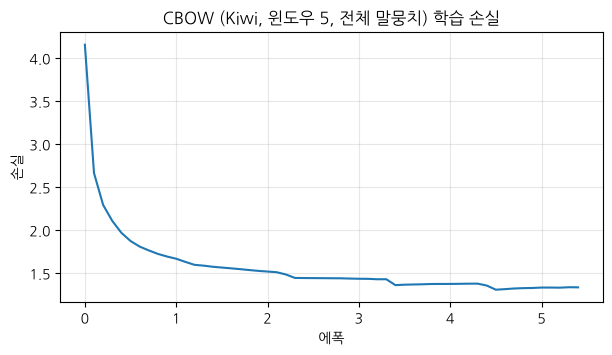

In [6]:
RUN_TRAINING = False
MAIN = 'results/cbow_kiwi_f1.0.pkl'   # 가장 좋았던 모델(전체 말뭉치). frac 0.5 기본 모델은 results/cbow_kiwi_main.pkl

if RUN_TRAINING:
    !python train_music.py --tokenizer kiwi --model cbow --window 5 --hidden 100 --batch 1000 --lr 0.003 --epoch 5 --min_count 10 --frac 1.0 --out cbow_kiwi_f1.0

with open(MAIN, 'rb') as f:
    params = pickle.load(f)
print(params['args'])
print('토큰 %d개, 학습 시간 %.0f분' % (params['tokens'], params['time_sec'] / 60))

plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(len(params['loss_list'])) / 10, params['loss_list'])
plt.xlabel('에폭'); plt.ylabel('손실'); plt.title('CBOW (Kiwi, 윈도우 5, 전체 말뭉치) 학습 손실'); plt.grid(alpha=.3)
plt.show()

## 5. 평가

### 5.1 비슷한 단어 (교재 `most_similar()`)

In [7]:
from common.util import most_similar, analogy

word_vecs = params['word_vecs'].astype(np.float32)
word_to_id, id_to_word = params['word_to_id'], params['id_to_word']

querys = ['피아노', '재즈', '교향곡', '쇼팽', '방탄소년단', '빌보드', '데뷔', '작곡가', '소프라노', '트로트']
for query in querys:
    most_similar(query, word_to_id, id_to_word, word_vecs, top=5)


[query] 피아노


 첼로: 0.782488226890564
 바이올린: 0.7010036706924438
 신시사이저: 0.6409136652946472
 쳄발로: 0.6388831734657288
 비올라: 0.6373361945152283

[query] 재즈
 클래식: 0.6790990233421326
 아방가르드: 0.6672245860099792
 블루스: 0.6420158743858337
 퓨전: 0.635114312171936
 뉴올리언스: 0.6277955174446106

[query] 교향곡


 연습곡: 0.693840742111206
 협주곡: 0.6823927164077759
 소나타: 0.6578784584999084
 글라주노프: 0.6481735110282898
 베토벤: 0.6400042772293091

[query] 쇼팽
 베토벤: 0.7219095230102539
 연습곡: 0.7083576917648315
 슈만: 0.7033485770225525
 모차르트: 0.6972284913063049
 멘델스존: 0.6909297704696655

[query] 방탄소년단


 빅뱅: 0.7433996796607971
 지드래곤: 0.6937966346740723
 레드벨벳: 0.6897926926612854
 포미닛: 0.6648743152618408
 케이팝: 0.6503956317901611

[query] 빌보드
 UK: 0.6688432097434998
 핫: 0.5938562750816345
 Billboard: 0.5901103019714355
 아이튠즈: 0.5402088761329651
 Hope: 0.5245643854141235

[query] 데뷔


 데뷰: 0.7330951690673828
 복귀: 0.6367588639259338
 컴백: 0.636604905128479
 발돋움: 0.6253443360328674
 전향: 0.6243304014205933

[query] 작곡가
 작곡자: 0.7068514823913574
 피아니스트: 0.7027367353439331
 음악가: 0.6773500442504883
 작사가: 0.6663348078727722
 프로듀서: 0.6323248147964478

[query] 소프라노


 테너: 0.7712977528572083
 바리톤: 0.7180079221725464
 성악가: 0.6773162484169006
 콜로라투라: 0.6232263445854187
 음역: 0.621010959148407

[query] 트로트
 정통: 0.6142691969871521
 발라드: 0.6134950518608093
 가요: 0.6131309270858765
 탱고: 0.5970721244812012
 설운도: 0.5895057916641235


### 5.2 유추 (교재 `analogy()`)

교재 `eval.py`처럼 학습된 `word_vecs`를 그대로 넣으면 결과가 엉뚱합니다(`피아노:피아니스트 = 바이올린:?` → `지휘자`, `영화배우`, …).
`analogy()`는 질의 벡터 `b − a + c`만 정규화하고 단어 행렬은 정규화하지 않은 채 내적하므로, **벡터 길이(노름)가 큰 단어**가 늘 위로 올라오기 때문입니다.
`출생`, `태어나다`, `이주`처럼 여러 문맥에 두루 나오는 단어가 노름이 커서 어느 질문에나 답으로 나옵니다.
교재 `common/util.py`의 `normalize()`로 단어 벡터를 먼저 정규화하면(코사인 유사도) 제대로 된 답이 나옵니다.

In [8]:
from common.util import normalize
print('정규화 전: 교재 eval.py 방식')
analogy('피아노', '피아니스트', '바이올린', word_to_id, id_to_word, word_vecs)

word_vecs_n = normalize(word_vecs.copy())
print('\n정규화 후')
analogy('피아노', '피아니스트', '바이올린', word_to_id, id_to_word, word_vecs_n)   # 피아노:피아니스트 = 바이올린:?
analogy('일본', '도쿄', '프랑스', word_to_id, id_to_word, word_vecs_n)          # 일본:도쿄 = 프랑스:?
analogy('미국', '빌보드', '일본', word_to_id, id_to_word, word_vecs_n)          # 미국:빌보드 = 일본:?
analogy('남성', '여성', '테너', word_to_id, id_to_word, word_vecs_n)            # 남성:여성 = 테너:?
analogy('독일', '독일어', '일본', word_to_id, id_to_word, word_vecs_n)          # 독일:독일어 = 일본:?
analogy('남자', '여자', '왕', word_to_id, id_to_word, word_vecs_n)              # 남자:여자 = 왕:?  (음악 말뭉치에는 왕·여왕 문맥이 거의 없다)
analogy('엑소', 'SM', '트와이스', word_to_id, id_to_word, word_vecs_n)           # 엑소:SM = 트와이스:?
analogy('모차르트', '오스트리아', '쇼팽', word_to_id, id_to_word, word_vecs_n)    # 모차르트:오스트리아 = 쇼팽:?

정규화 전: 교재 eval.py 방식

[analogy] 피아노:피아니스트 = 바이올린:?
 후임: 6.647072792053223
 지휘자: 6.471342086791992
 바이올리니스트: 5.865968704223633
 본관: 5.8209123611450195
 주자: 5.780092239379883

정규화 후

[analogy] 피아노:피아니스트 = 바이올린:?
 바이올리니스트: 0.695626437664032
 조각가: 0.6338944435119629
 오르가니스트: 0.5974520444869995
 첼리스트: 0.5951471328735352
 성악가: 0.5947331786155701

[analogy] 일본:도쿄 = 프랑스:?
 파리: 0.630908727645874
 하노이: 0.566031813621521
 취리히: 0.5289055109024048
 뒤셀도르프: 0.5138541460037231
 팔레: 0.5086285471916199

[analogy] 미국:빌보드 = 일본:?
 오리콘: 0.46307188272476196
 TOKIO: 0.45385581254959106
 ZARD: 0.4518551528453827
 너에게: 0.44624191522598267
 나미에: 0.43633538484573364

[analogy] 남성:여성 = 테너:?
 소프라노: 0.611426591873169
 바리톤: 0.600914478302002
 모나코: 0.5056924819946289
 성악가: 0.5037431716918945
 아이다: 0.5009674429893494

[analogy] 독일:독일어 = 일본:?
 일본어: 0.5504045486450195
 번역: 0.5457748174667358
 중국어: 0.5375289916992188
 한국어: 0.5261046886444092
 블리치: 0.46819281578063965

[analogy] 남자:여자 = 왕:?
 시신: 0.47199809551239014
 크레인: 0

### 5.3 정량 평가

몇 개를 눈으로 보는 것만으로는 설정끼리 비교하기 어려워서 평가셋을 직접 만들었습니다(`eval/build_testsets.py`, 사실관계는 위키백과 기준).

* **유추 374문항** (`eval/music_analogy.txt`, 정규화한 벡터로 풂, Google analogy 형식 `a b c d`): 7개 범주의 짝을 서로 엮어 만듦
  * 악기→연주자(피아노:피아니스트), 그룹→소속사(엑소:SM), 국가→수도, 국가→언어, 국가→음악 차트(미국:빌보드), 작곡가→국적, 남성→여성
  * `b − a + c`와 코사인 유사도가 가장 큰 단어(a·b·c 제외, 교재 `analogy()`와 같은 방식)가 정답이면 top-1, 상위 5개 안에 있으면 top-5
  * 정답이 질문 단어와 같아지는 문제(엑소:SM = 샤이니:SM)는 교재 방식으로는 풀 수 없어서 뺐습니다.
* **범주 군집 평가** (`eval/music_categories.txt`): 악기·장르·작곡가·K팝 그룹·국가·곡 형식·음악 직업 7개 범주, 84단어.
  단어마다 평가 단어 전체 중 가장 가까운 5개가 같은 범주인 비율(precision@5). 무작위로 고르면 약 0.14입니다.

In [9]:
import eval_music as E
p = E.load_params(MAIN)

a = E.eval_analogy(p)
print('%-10s %6s %6s %6s' % ('범주', '문항', 'top1', 'top5'))
for k, v in a.items():
    print('%-10s %3d/%-3d %6.3f %6.3f' % (k, v['covered'], v['total'], v['top1'], v['top5']))

print()
c = E.eval_categories(p)
for k, v in c.items():
    print('%-8s P@5 = %.3f' % (k, v))

범주             문항   top1   top5
악기-연주자      42/42   0.333  0.833
그룹-소속사      94/94   0.670  0.957
국가-수도       56/56   0.321  0.661
국가-언어       30/30   0.367  0.867
국가-음악차트      6/6    0.667  1.000
작곡가-국적      90/90   0.289  0.756
남성-여성       56/56   0.768  0.839
전체         374/374  0.479  0.826

악기       P@5 = 0.983
장르       P@5 = 0.914
작곡가      P@5 = 0.917
K팝그룹     P@5 = 0.943
국가       P@5 = 0.967
곡형식      P@5 = 0.480
음악직업     P@5 = 0.945
전체       P@5 = 0.889


In [10]:
# 틀린 유추 문제 몇 개: 무엇과 헷갈렸나
qs = E.load_analogy()
wrong = [(cat, q, E.solve_analogy(p, *q[:3])) for cat, q in qs
         if all(w in p['word_to_id'] for w in q) and E.solve_analogy(p, *q[:3])[0] != q[3]]
rng = np.random.RandomState(0)
for i in rng.choice(len(wrong), 12, replace=False):
    cat, (qa, qb, qc, qd), pred = wrong[i]
    print('[%s] %s:%s = %s:?  정답 %s  예측 %s' % (cat, qa, qb, qc, qd, pred[:3]))

[국가-수도] 이탈리아:로마 = 일본:?  정답 도쿄  예측 ['미야자키', '메이지', '일본레코드대상']
[악기-연주자] 첼로:첼리스트 = 기타:?  정답 기타리스트  예측 ['피아니스트', '유키스', '성악가']
[그룹-소속사] 샤이니:SM = 아이콘:?  정답 YG  예측 ['개념', 'YG', '명실상부']
[국가-언어] 스페인:스페인어 = 프랑스:?  정답 프랑스어  예측 ['중국어', '프랑스어', '영어']
[작곡가-국적] 베르디:이탈리아 = 하이든:?  정답 오스트리아  예측 ['독일', '오스트리아', '소련']
[작곡가-국적] 바그너:독일 = 푸치니:?  정답 이탈리아  예측 ['폴란드', '프랑스', '이탈리아']
[작곡가-국적] 차이콥스키:러시아 = 브람스:?  정답 독일  예측 ['소련', '독일', '카자흐스탄']
[작곡가-국적] 베토벤:독일 = 차이콥스키:?  정답 러시아  예측 ['이탈리아', '프랑스', '헝가리']
[국가-수도] 프랑스:파리 = 독일:?  정답 베를린  예측 ['잘츠부르크', '베를린', '라이프치히']
[악기-연주자] 드럼:드러머 = 첼로:?  정답 첼리스트  예측 ['비올라', '솔리스트', '엘가']
[악기-연주자] 기타:기타리스트 = 피아노:?  정답 피아니스트  예측 ['바이올리니스트', '피아니스트', '마주르카']
[악기-연주자] 바이올린:바이올리니스트 = 드럼:?  정답 드러머  예측 ['베이시스트', '기타리스트', '롤러코스터']


## 6. 비교 실험

같은 평가셋으로 설정을 하나씩 바꿔 비교합니다. 모두 5에폭, `hidden_size=100`, `min_count=10`, 배치 1000입니다.

| 실험 | 바꾼 것 |
|---|---|
| 학습률 | Adam lr 0.001 vs 0.003 (2에폭) |
| 토크나이저 | 규칙 기반 vs Kiwi (CBOW, 윈도우 5, frac 0.5) |
| 모델·윈도우 | CBOW 윈도우 2 / 5, Skip-gram 윈도우 2 (Kiwi, frac 0.5) |
| 말뭉치 크기 | frac 0.1 / 0.25 / 0.5 / 1.0 (CBOW, Kiwi, 윈도우 5) |

In [11]:
RUNS = [('lrtest_0.001', '학습률 0.001 (2에폭)'), ('lrtest_0.003', '학습률 0.003 (2에폭)'), ('cbow_rule_main', '규칙 / CBOW w5'), ('cbow_kiwi_main', 'Kiwi / CBOW w5'), ('cbow_kiwi_w2', 'Kiwi / CBOW w2'), ('sg_kiwi_w2', 'Kiwi / Skip-gram w2'), ('cbow_kiwi_f0.1', '크기 0.1 / CBOW w5'), ('cbow_kiwi_f0.25', '크기 0.25 / CBOW w5'), ('cbow_kiwi_main', '크기 0.5 / CBOW w5'), ('cbow_kiwi_f1.0', '크기 1.0 / CBOW w5')]
rows = []
for name, label in RUNS:
    path = 'results/%s.pkl' % name
    if not os.path.exists(path):
        print('없음:', path); continue
    q = E.load_params(path)
    a = E.eval_analogy(q)['전체']; c = E.eval_categories(q)['전체']
    rows.append((label, q['tokens'], len(q['word_to_id']), q['time_sec'] / 60, a['top1'], a['top5'], a['covered'], c, q['loss_list'][-1]))
print('%-28s %9s %7s %6s %6s %6s %5s %6s %6s' % ('설정', '토큰', '어휘', '분', 'top1', 'top5', '문항', 'P@5', '손실'))
for r in rows:
    print('%-28s %9d %7d %6.1f %6.3f %6.3f %5d %6.3f %6.2f' % r)

설정                                  토큰      어휘      분   top1   top5    문항    P@5     손실
학습률 0.001 (2에폭)                2514443   12687   11.4  0.128  0.291   374  0.772   1.99
학습률 0.003 (2에폭)                2514443   12687   11.3  0.262  0.564   374  0.802   1.66
규칙 / CBOW w5                   2194363   16220   28.0  0.321  0.603   358  0.760   1.43
Kiwi / CBOW w5                 2514443   12687   29.2  0.358  0.660   374  0.835   1.44
Kiwi / CBOW w2                 2514443   12687   20.5  0.230  0.540   374  0.896   1.22
Kiwi / Skip-gram w2            2514443   12687   45.9  0.345  0.652   374  0.880   8.11
크기 0.1 / CBOW w5                502842    4190    4.6  0.163  0.332   202  0.731   1.81
크기 0.25 / CBOW w5              1249778    7922   12.8  0.226  0.479   332  0.785   1.57
크기 0.5 / CBOW w5               2514443   12687   29.2  0.358  0.660   374  0.835   1.44
크기 1.0 / CBOW w5               5172919   20276   72.2  0.479  0.826   374  0.889   1.34


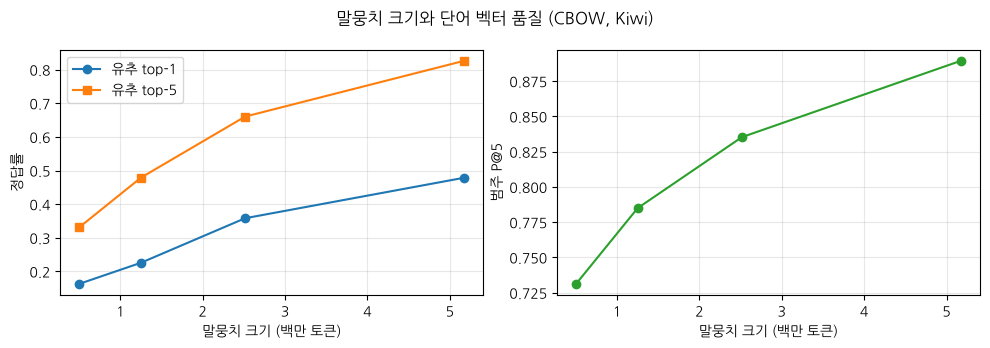

In [12]:
# 말뭉치 크기에 따른 변화
size_runs = [r for r in rows if r[0].startswith('크기')]
if size_runs:
    toks = [r[1] / 1e6 for r in size_runs]
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(toks, [r[4] for r in size_runs], 'o-', label='유추 top-1')
    ax[0].plot(toks, [r[5] for r in size_runs], 's-', label='유추 top-5')
    ax[0].set_xlabel('말뭉치 크기 (백만 토큰)'); ax[0].set_ylabel('정답률'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(toks, [r[7] for r in size_runs], 'o-', color='C2')
    ax[1].set_xlabel('말뭉치 크기 (백만 토큰)'); ax[1].set_ylabel('범주 P@5'); ax[1].grid(alpha=.3)
    plt.suptitle('말뭉치 크기와 단어 벡터 품질 (CBOW, Kiwi)'); plt.tight_layout(); plt.show()

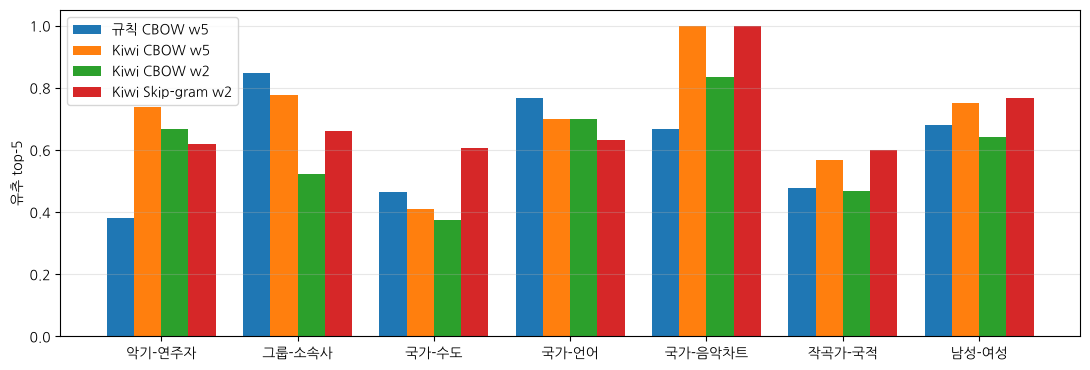

In [13]:
# 범주별 유추 정답률(top-5): 토크나이저와 모델 비교
compare = [('cbow_rule_main', '규칙 CBOW w5'), ('cbow_kiwi_main', 'Kiwi CBOW w5'), ('cbow_kiwi_w2', 'Kiwi CBOW w2'), ('sg_kiwi_w2', 'Kiwi Skip-gram w2')]
cats = [k for k in E.eval_analogy(p).keys() if k != '전체']
fig, ax = plt.subplots(figsize=(11, 3.8))
w = 0.8 / len(compare)
for j, (name, label) in enumerate(compare):
    path = 'results/%s.pkl' % name
    if not os.path.exists(path): continue
    a = E.eval_analogy(E.load_params(path))
    ax.bar(np.arange(len(cats)) + j * w, [a[k]['top5'] for k in cats], w, label=label)
ax.set_xticks(np.arange(len(cats)) + w * (len(compare) - 1) / 2); ax.set_xticklabels(cats)
ax.set_ylabel('유추 top-5'); ax.legend(); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()

## 7. 단어 벡터 2차원 시각화

범주 평가에 쓴 84단어를 2차원으로 줄여 범주별 색으로 그립니다. 왼쪽은 김소월 예제와 같은 SVD, 오른쪽은 t-SNE입니다.

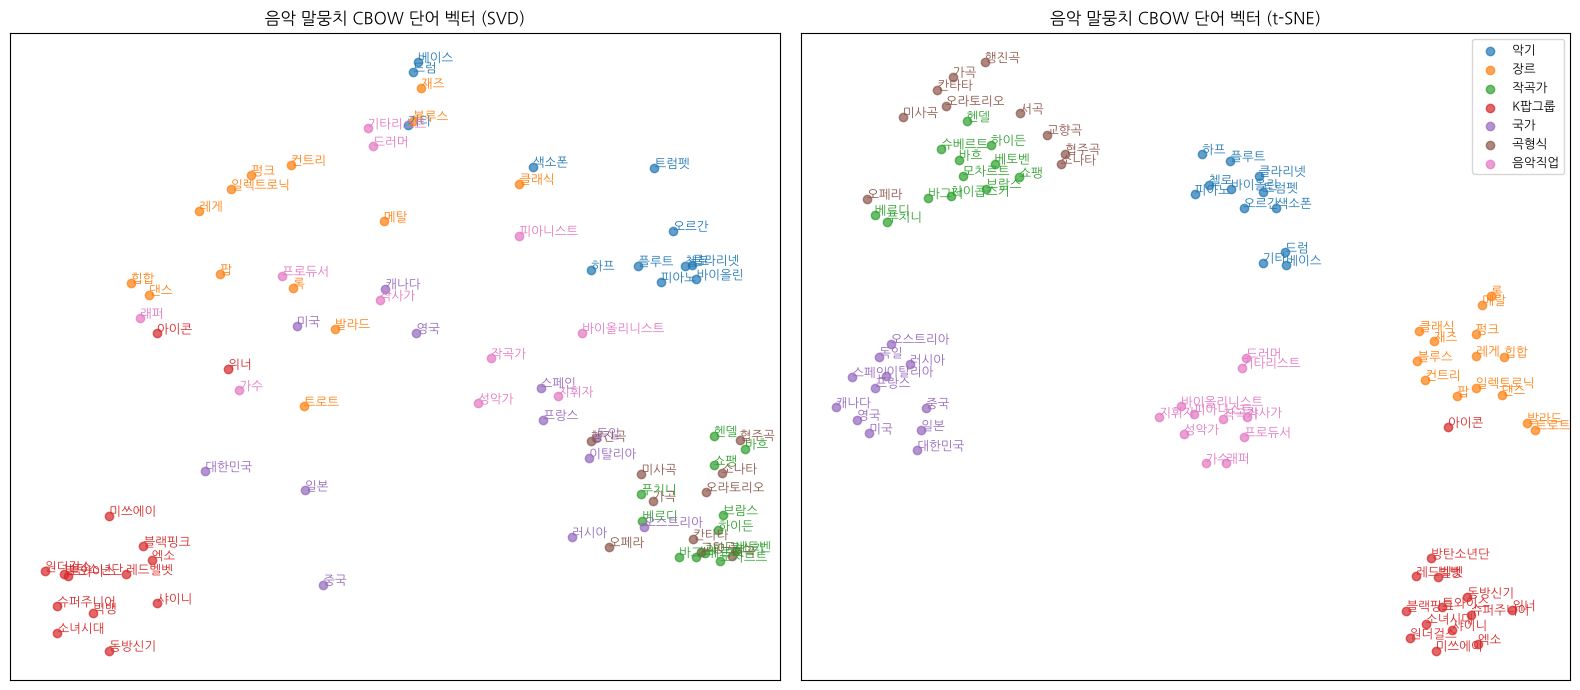

In [14]:
from sklearn.manifold import TSNE
cats = E.load_categories()
words, labels = [], []
for name, ws in cats.items():
    for w in ws:
        if w in p['word_to_id'] and w not in words:
            words.append(w); labels.append(name)
X = p['W'][[p['word_to_id'][w] for w in words]]

Xc = X - X.mean(axis=0)
U, S, V = np.linalg.svd(Xc)
Y_svd = U[:, :2] * S[:2]
Y_tsne = TSNE(n_components=2, perplexity=10, random_state=0, init='pca', metric='cosine').fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
names = list(cats.keys())
for ax, Y, title in [(axes[0], Y_svd, 'SVD'), (axes[1], Y_tsne, 't-SNE')]:
    for k, name in enumerate(names):
        idx = [i for i, l in enumerate(labels) if l == name]
        ax.scatter(Y[idx, 0], Y[idx, 1], color='C%d' % k, label=name, alpha=.7)
        for i in idx:
            ax.annotate(words[i], (Y[i, 0], Y[i, 1]), fontsize=9, color='C%d' % k)
    ax.set_title('음악 말뭉치 CBOW 단어 벡터 (%s)' % title); ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(loc='best', fontsize=9)
plt.tight_layout(); plt.savefig('figures/tsne_categories.png', dpi=120); plt.show()

## 8. 고찰

위 표의 숫자를 기준으로 정리합니다(모두 시드 하나로 1회 학습한 결과라 차이가 작은 것은 오차 범위일 수 있습니다).

**1. 말뭉치 크기가 가장 큰 영향을 줬다.** 같은 CBOW 설정에서 문서를 10% → 25% → 50% → 100%로 늘리자 유추 top-5가 0.33 → 0.48 → 0.66 → 0.83, 범주 P@5가 0.73 → 0.79 → 0.84 → 0.89로 꾸준히 올랐고 아직 포화되지 않았습니다.
작은 말뭉치에서는 평가 단어 자체가 `min_count` 미만이라 풀 수 있는 문항도 줄었습니다(10%일 때 374문항 중 202문항).
다만 말뭉치가 커지면 같은 5에폭이라도 갱신 횟수와 어휘도 함께 늘어나므로, 순수한 "데이터 양"의 효과만은 아닙니다.
1.3만 토큰짜리 김소월 예제에서 `님`의 이웃이 `몹쓸`, `물가`였던 것과 달리, 이 말뭉치에서는 `피아노 → 첼로, 바이올린, 신시사이저, 쳄발로`, `소프라노 → 테너, 바리톤, 성악가`, `방탄소년단 → 빅뱅, 지드래곤, 레드벨벳`처럼 납득할 만한 이웃이 나오고, `미국:빌보드 = 일본:오리콘`, `엑소:SM = 트와이스:JYP` 같은 분야 지식 유추도 맞힙니다.
반면 `남자:여자 = 왕:?`은 끝까지 틀렸는데, 음악 문서에는 왕·여왕이 나오는 문맥이 거의 없기 때문입니다. 단어 벡터는 말뭉치가 다루는 세계만큼만 압니다.

**2. 형태소 분석(Kiwi)이 규칙 기반보다 나았다.** 같은 문서에서 Kiwi는 어휘 1.27만 개, `<unk>` 6%인 반면 규칙 기반은 1.62만 개, 13%였습니다.
규칙 기반은 `작곡가이자`, `그룹이다`, `데뷔한`처럼 어미가 붙은 형태가 모두 다른 단어가 되어 같은 단어의 통계가 흩어집니다.
그 결과 유추 top-5 0.66 vs 0.60, 범주 P@5 0.84 vs 0.76으로 Kiwi가 앞섰고, 특히 `작곡가`(0.83 vs 0.67)와 `음악직업`(0.84 vs 0.58) 범주, 악기→연주자 유추(top-5 0.74 vs 0.38) 차이가 컸습니다.
반대로 Kiwi는 `빅히트`를 `빅`+`히트`로 쪼개는 등 고유명사를 자르는 문제가 있어 그룹→소속사 유추에서는 규칙 기반이 더 높았습니다(0.85 vs 0.78).

**3. 윈도우 크기에 따라 잡아내는 관계가 달랐다.** 윈도우 2는 범주 P@5가 0.90으로 윈도우 5(0.84)보다 높았지만 유추 top-5는 0.54로 더 낮았습니다.
좁은 문맥은 "같은 자리에 들어갈 수 있는 단어", 즉 같은 종류(악기끼리, 작곡가끼리)를 잘 묶고, 넓은 문맥은 그룹–소속사, 작곡가–국적처럼 **함께 등장하는 관계**를 더 잘 담는 것으로 보입니다.

**4. Skip-gram은 CBOW보다 유추에 강했지만 2배 넘게 느렸다.** 윈도우 2에서 Skip-gram은 유추 top-5 0.65로 CBOW(0.54)보다 높았고, 특히 국가→수도(0.61 vs 0.38)와 곡 형식 범주처럼 드문 단어가 많은 경우에 좋았습니다.
Skip-gram은 맥락 단어마다 손실을 따로 계산해 드문 단어도 더 많은 학습 신호를 받기 때문입니다. 대신 학습 시간은 46분으로 CBOW(20분)의 2.2배였습니다.

**5. 속도 개선 기법의 효과와 한계.** Embedding 계층과 네거티브 샘플링 덕분에 어휘 1~2만 개, 토큰 500만 개를 NumPy만으로 학습할 수 있었습니다(Softmax였다면 출력층 하나가 매번 1만 개 단어 전체를 계산).
그래도 교재 구현은 `Embedding.backward()`와 `Adam`이 매 반복마다 (어휘 수 × 100) 행렬 전체를 다뤄서, 반복 1회 비용이 어휘 수에 비례했습니다.
그래서 배치를 1000으로 키우고 학습률을 0.003으로 올렸는데, 같은 2에폭에서 lr 0.001(유추 top-5 0.29)보다 0.003(0.56)이 크게 나았습니다. 배치를 키워 갱신 횟수가 줄어든 만큼 학습률을 키워야 했습니다.

**6. 평가에서 배운 점.** 교재 `analogy()`에 정규화하지 않은 벡터를 넣으면 노름이 큰 단어(`출생`, `태어나다`, `이주`)가 어느 질문에나 답으로 나와서 유추가 거의 다 틀립니다. `normalize()` 후 코사인 유사도로 풀어야 했습니다.
틀린 문제를 보면 `브람스:독일 = 차이콥스키:? → 오스트리아`처럼 같은 범주 안에서 헷갈린 경우가 많아, 관계 방향은 잡았지만 세부 구분이 약했습니다.
`곡형식` 범주(칸타타, 오라토리오, 미사곡 …)는 모든 설정에서 P@5가 0.3~0.6으로 가장 낮았는데, 이 단어들은 등장 횟수가 적고 `작곡하다`, `초연` 같은 비슷한 문맥을 작곡가·악기와 함께 써서 범주 경계가 흐립니다.

**한계와 더 해 볼 것.** 평가셋은 직접 만든 소규모(유추 374문항, 84단어)라 일반적인 품질 지표는 아니고, 실험마다 한 번씩만 돌렸습니다.
전체 말뭉치(520만 토큰)로 Skip-gram을 학습하거나, 에폭·`hidden_size`를 바꿔 보거나, Kiwi에 고유명사 사전(`빅히트`, `SM엔터테인먼트`)을 추가하면 더 나아질 것으로 예상합니다.
